**Setup:** Pfade zu den drei JSONL-Dateien und zur Referenz-CSV festlegen und Bibliotheken importieren. Die Hilfsfunktion `to_list` macht aus einem Text wie `"A, B"` eine Liste `["A", "B"]`, leere Werte werden zu `[]`.

In [18]:
TRAIN = "../../data_in/train.jsonl"
VAL   = "../../data_in/validation.jsonl"
TEST  = "../../data_in/test.jsonl"
REF   = "../reference/aegis_referenz_id.csv"

import re
import pandas as pd
import matplotlib.pyplot as plt

def to_list(s):
    """'A, B' -> ['A', 'B'];  leer/NaN -> []"""
    if s is None or (isinstance(s, float) and pd.isna(s)) or not str(s).strip():
        return []
    return [c.strip() for c in str(s).split(",") if c.strip()]

In [19]:
ref = pd.read_csv(REF, sep=None, engine="python")
ref = ref[ref["taxonomie"] == "aegis"]

ersetzen = {"Kriminalitaet": "Kriminalität", "Belaestigung": "Belästigung", "Privatsphaere": "Privatsphäre"}
for alt, neu in ersetzen.items():
    ref["familie_eigene_gruppierung"] = ref["familie_eigene_gruppierung"].str.replace(alt, neu)

for _, r in ref.iterrows():
    print(f"{r.kuerzel} & {r.label} & {r.ebene_im_paper} & {r.familie_eigene_gruppierung} & "
          f"{r.finanzrelevanz_eigene_einschaetzung} & {r.begruendung_finanzrelevanz} \\\\")

S1 & Violence & Kern & Gewalt und Waffen & gering & Körperliche Gewalt, Finanzbezug nur ausnahmsweise \\
S2 & Sexual & Kern & Sexuelle Inhalte & gering & Kein inhaltlicher Finanzbezug \\
S3 & Criminal Planning/Confessions & Kern & Kriminalität und Betrug & mittel & Umfasst auch Finanzkriminalität, überwiegend aber andere Delikte (z. B. Diebstahl, Banküberfall) \\
S4 & Guns and Illegal Weapons & Kern & Gewalt und Waffen & gering & Kein inhaltlicher Finanzbezug \\
S5 & Controlled/Regulated Substances & Kern & Kriminalität und Betrug & gering & Drogen und regulierte Stoffe, Finanzbezug nur ausnahmsweise \\
S6 & Suicide and Self Harm & Kern & Selbstschaden & gering & Finanzbezug nur ausnahmsweise (z. B. Schulden als Anlass) \\
S7 & Sexual (minor) & Kern & Sexuelle Inhalte & gering & Kein inhaltlicher Finanzbezug \\
S8 & Hate/Identity Hate & Kern & Hass und Belästigung & gering & Kein inhaltlicher Finanzbezug \\
S9 & PII/Privacy & Kern & Privatsphäre & hoch & Betrifft direkt Finanzdaten wie

**Daten laden:** train, val und test als DataFrames einlesen und für jeden Split Größe (Zeilen, Spalten) sowie die Verteilung von `safe`/`unsafe` ausgeben.

In [20]:
train = pd.read_json(TRAIN, lines=True)
val = pd.read_json(VAL, lines=True)
test = pd.read_json(TEST, lines=True)

print(train.shape, train["prompt_label"].value_counts())
print(val.shape, val["prompt_label"].value_counts())
print(test.shape, test["prompt_label"].value_counts())

(1643, 18) prompt_label
unsafe    1477
safe       166
Name: count, dtype: int64
(1700, 12) prompt_label
unsafe    951
safe      749
Name: count, dtype: int64
(2364, 12) prompt_label
unsafe    1300
safe      1064
Name: count, dtype: int64


**Kategorien pro Split zählen:** Die Kategorien werden mit `to_list` in Listen umgewandelt (neue Spalte `cats`). `explode()` macht daraus eine Zeile pro Kategorie, `value_counts()` zählt sie. Ergebnis: Kategorien als Zeilen, Splits als Spalten.

In [22]:
splits = {"train": train, "val": val, "test": test}

counts_per_split = {}
for name, df in splits.items():
    df["cats"] = df["violated_categories"].apply(to_list)
    counts_per_split[name] = df["cats"].explode().value_counts()

pd.DataFrame(counts_per_split).fillna(0).astype(int)

,train,val,test
cats,,,
Controlled/Regulated Substances,185,124,212
Copyright/Trademark/Plagiarism,3,3,6
Criminal Planning/Confessions,886,384,570
Fraud/Deception,52,36,42
Guns and Illegal Weapons,137,69,100
Harassment,236,119,146
Hate/Identity Hate,408,141,189
High Risk Gov Decision Making,15,3,4
Illegal Activity,5,140,140


**Balkendiagramm Train:** Kategorie-Häufigkeiten im Train-Split als liegende Balken, größter Wert oben, Zahlen an den Balken. Zum Schluss wird die häufigste Kategorie ausgegeben.

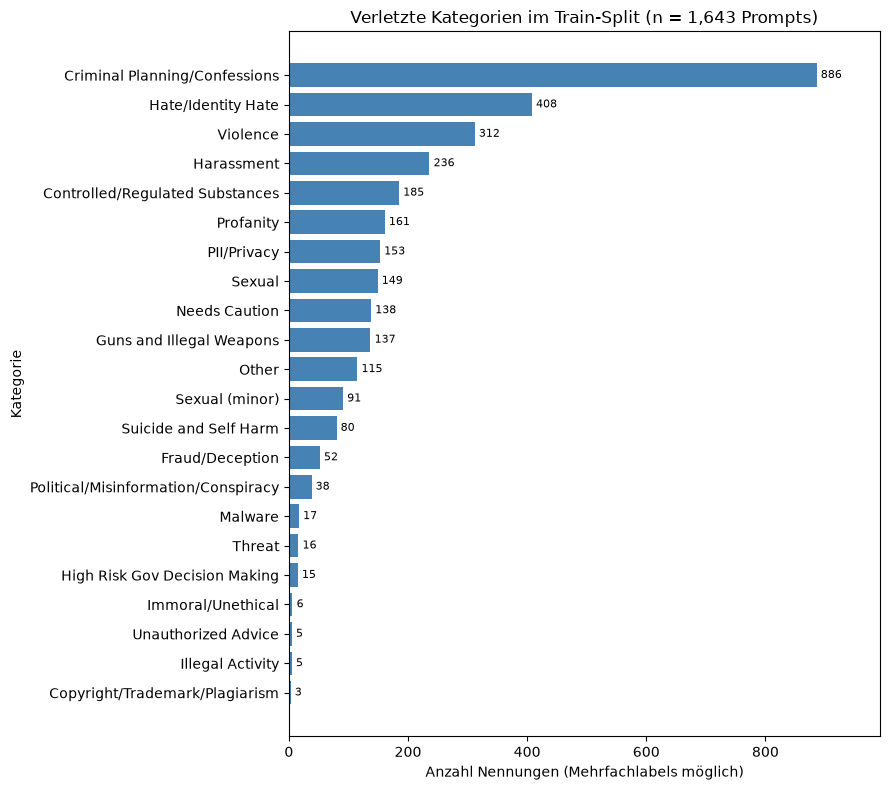

Oben: Criminal Planning/Confessions


In [23]:
counts = train["cats"].explode().value_counts()
plot_counts = counts.sort_values(ascending=True)   # barh zeichnet von unten nach oben -> größter Wert oben

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(plot_counts.index, plot_counts.values, color="steelblue")
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_xlabel("Anzahl Nennungen (Mehrfachlabels möglich)")
ax.set_ylabel("Kategorie")
ax.set_title(f"Verletzte Kategorien im Train-Split (n = {len(train):,} Prompts)")
ax.set_xlim(0, plot_counts.max() * 1.12)
plt.tight_layout()
plt.show()

print("Oben:", counts.index[0])

**Kategorien zu Familien zuordnen:** Referenz-CSV einlesen (Trennzeichen wird automatisch erkannt), nur die Aegis-Kategorien behalten (die ExpGuard-Kategorien folgen später für OOD) und daraus drei Hilfsobjekte bauen: Kategorie → Familie, Kategorie → Finanzrelevanz und die Menge der Kategorien, die in Grafiken nicht gezählt werden (Spalte `in_grafiken`, betrifft Needs Caution). `to_long` erzeugt eine Zeile pro Kombination aus Prompt und Kategorie und ergänzt die Familie. Kategorien ohne Zuordnung werden gemeldet. Am Ende: Anzahl und Anteil je Familie, einmal mit und einmal ohne die nicht gezählten Kategorien.

In [25]:
# sep=None erkennt Komma oder Semikolon automatisch
ref = pd.read_csv(REF, sep=None, engine="python")
ref.columns = ref.columns.str.strip()
ref = ref[ref["taxonomie"].str.strip() == "aegis"].copy()   # nur Aegis (ExpGuard kommt für OOD)
ref["label"] = ref["label"].str.strip()

familie_map = dict(zip(ref["label"], ref["familie_eigene_gruppierung"].str.strip()))
finanz_map = dict(zip(ref["label"], ref["finanzrelevanz_eigene_einschaetzung"].str.strip()))
in_grafiken = ref["in_grafiken"].astype(str).str.strip().str.lower() == "true"
nicht_in_grafiken = set(ref.loc[~in_grafiken, "label"])
print("In Grafiken nicht gezählt:", nicht_in_grafiken)

def to_long(df):
    """Eine Zeile pro (Prompt, Kategorie) mit Familie."""
    long = (df[["prompt_label", "cats"]]
            .explode("cats")
            .dropna(subset=["cats"])
            .rename(columns={"cats": "kategorie"}))
    long["familie"] = long["kategorie"].map(familie_map)
    return long

train_long = to_long(train)

fehlend = train_long.loc[train_long["familie"].isna(), "kategorie"].unique()
if len(fehlend):
    print("Ohne Familie in der Referenz:", fehlend)

fam_counts = train_long["familie"].value_counts()
fam_share = train_long["familie"].value_counts(normalize=True).mul(100).round(1)

# Dieselben Anteile ohne die nicht gezählten Kategorien (für Text und Treemap)
fuer_grafiken = train_long[~train_long["kategorie"].isin(nicht_in_grafiken)]

pd.DataFrame({"n": fam_counts,
              "anteil_%": fam_share})

In Grafiken nicht gezählt: set()


,n,anteil_%
familie,,
Kriminalitaet und Betrug,1145,35.7
Hass und Belaestigung,805,25.1
Gewalt und Waffen,465,14.5
Sonstiges,259,8.1
Sexuelle Inhalte,240,7.5
Privatsphaere,153,4.8
Selbstschaden,80,2.5
Desinformation und Manipulation,38,1.2
Beratung und Regulierung,23,0.7


In [27]:
unsafe = train[train["prompt_label"] == "unsafe"]
long = unsafe[["cats"]].explode("cats").dropna()
long["n_cats"] = unsafe.loc[long.index, "cats"].str.len()

stats = long.groupby("cats").agg(
    nennungen=("n_cats", "size"),
    anteil_allein=("n_cats", lambda s: (s == 1).mean() * 100),
).round(1).sort_values("anteil_allein")
stats

,nennungen,anteil_allein
cats,,
Threat,16,0.0
Illegal Activity,5,0.0
Immoral/Unethical,6,0.0
Needs Caution,138,0.0
Other,115,0.0
Violence,312,0.6
Sexual (minor),91,2.2
Sexual,149,2.7
Fraud/Deception,52,3.8


## Schritt 7. Splits vergleichen

**Familienanteile vergleichen:** Prozentualer Anteil jeder Familie pro Split und die Abweichung von val und test gegenüber train in Prozentpunkten (pp).

In [29]:
longs = {name: to_long(df) for name, df in splits.items()}

fam_vergleich = pd.concat(
    {name: long["familie"].value_counts(normalize=True) for name, long in longs.items()},
    axis=1).fillna(0).mul(100).round(1)
fam_vergleich = fam_vergleich.sort_values("train", ascending=False)

# Abweichung in Prozentpunkten gegenüber train
fam_vergleich["Δ val (pp)"]  = (fam_vergleich["val"]  - fam_vergleich["train"]).round(1)
fam_vergleich["Δ test (pp)"] = (fam_vergleich["test"] - fam_vergleich["train"]).round(1)
fam_vergleich

,train,val,test,Δ val (pp),Δ test (pp)
familie,,,,,
Kriminalitaet und Betrug,35.7,34.0,34.7,-1.7,-1.0
Hass und Belaestigung,25.1,17.0,15.5,-8.1,-9.6
Gewalt und Waffen,14.5,11.5,12.3,-3.0,-2.2
Sonstiges,8.1,11.3,14.7,3.2,6.6
Sexuelle Inhalte,7.5,6.1,5.1,-1.4,-2.4
Privatsphaere,4.8,5.0,5.4,0.2,0.6
Selbstschaden,2.5,5.0,4.0,2.5,1.5
Desinformation und Manipulation,1.2,6.5,5.1,5.3,3.9
Beratung und Regulierung,0.7,3.6,3.1,2.9,2.4


**Grafik und Auffälligkeiten:** Familienanteile der drei Splits als gruppierte Balken. Danach werden die Familien gelistet, die um mehr als 2 pp von train abweichen.

In [31]:
longs = {name: to_long(df) for name, df in splits.items()}

kat_vergleich = pd.concat(
    {name: long["kategorie"].value_counts(normalize=True) for name, long in longs.items()},
    axis=1).fillna(0).mul(100).round(1)
kat_vergleich = kat_vergleich.sort_values("train", ascending=False)

# Abweichung in Prozentpunkten gegenüber train
kat_vergleich["Δ val (pp)"]  = (kat_vergleich["val"]  - kat_vergleich["train"]).round(1)
kat_vergleich["Δ test (pp)"] = (kat_vergleich["test"] - kat_vergleich["train"]).round(1)
kat_vergleich

,train,val,test,Δ val (pp),Δ test (pp)
kategorie,,,,,
Criminal Planning/Confessions,27.6,19.0,20.3,-8.6,-7.3
Hate/Identity Hate,12.7,7.0,6.7,-5.7,-6.0
Violence,9.7,6.2,7.1,-3.5,-2.6
Harassment,7.4,5.9,5.2,-1.5,-2.2
Controlled/Regulated Substances,5.8,6.1,7.6,0.3,1.8
Profanity,5.0,4.2,3.6,-0.8,-1.4
PII/Privacy,4.8,5.0,5.4,0.2,0.6
Sexual,4.6,2.7,3.2,-1.9,-1.4
Needs Caution,4.3,4.1,9.1,-0.2,4.8


In [ ]:
for name in ["val", "test"]:
    tvd = kat_vergleich[f"Δ {name} (pp)"].abs().sum() / 2
    print(f"TVD train → {name}: {tvd:.1f} %")

TVD train → val: 14.1 %
TVD train → test: 15.1 %


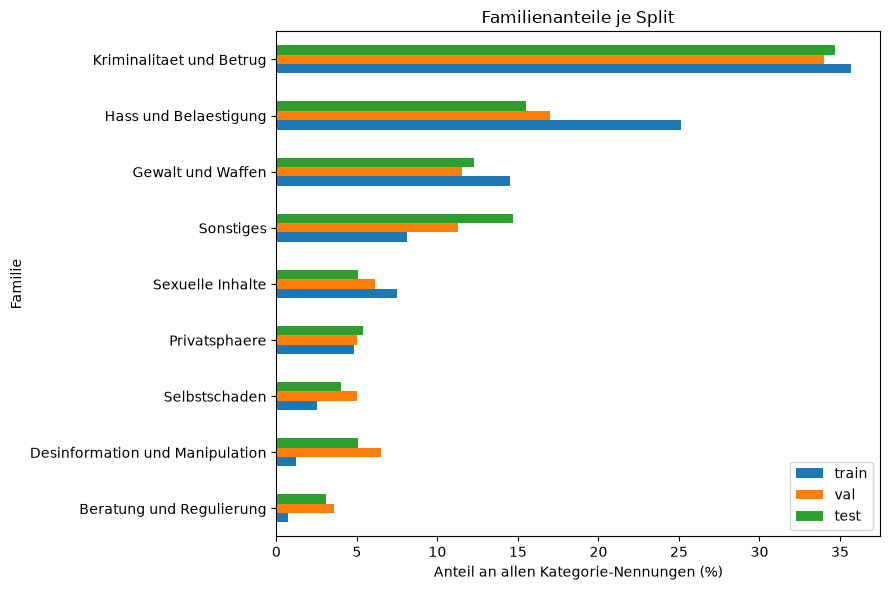

Abweichung > 2 pp:
                                  train   val  test  Δ val (pp)  Δ test (pp)
familie                                                                    
Hass und Belaestigung             25.1  17.0  15.5        -8.1         -9.6
Gewalt und Waffen                 14.5  11.5  12.3        -3.0         -2.2
Sonstiges                          8.1  11.3  14.7         3.2          6.6
Sexuelle Inhalte                   7.5   6.1   5.1        -1.4         -2.4
Selbstschaden                      2.5   5.0   4.0         2.5          1.5
Desinformation und Manipulation    1.2   6.5   5.1         5.3          3.9
Beratung und Regulierung           0.7   3.6   3.1         2.9          2.4


In [30]:
ax = fam_vergleich[["train", "val", "test"]].iloc[::-1].plot.barh(figsize=(9, 6))
ax.set_xlabel("Anteil an allen Kategorie-Nennungen (%)")
ax.set_ylabel("Familie")
ax.set_title("Familienanteile je Split")
plt.tight_layout()
plt.show()

auffaellig = fam_vergleich[(fam_vergleich[["Δ val (pp)", "Δ test (pp)"]].abs() > 2).any(axis=1)]
print("Abweichung > 2 pp:\n", auffaellig if len(auffaellig) else "keine")

## Schritt 8. Finanz-Schlüsselwörter

**Finanz-Schlüsselwörter suchen:** Regulärer Ausdruck für Finanzbegriffe (Aktie, Konto, Steuer, Bank usw.) und Markierung der Prompts mit Treffer in jedem Split. Die Gruppe ist mit `(?:...)` geschrieben (nicht erfassend), dadurch verschwindet die `UserWarning`.

In [14]:
# Wortanfang (\b), danach beliebige Endung -> erfasst auch Komposita wie "Steuerhinterziehung"
finanz_re = re.compile(r"""
    \b(?:
        \w*(?:konto|konten|kontos)\b            # Bankkonto, Girokonto, Konten
      | \w*kredit\w*                            # Kredit, Kreditkarte, Kreditauskunft
      | geldw(?:ä|ae)sche\w* | geld\s?wasch\w*  # Geldwäsche, Geld waschen
      | insider(?:handel|geschäft|geschaeft)\w*
      | aktie\w* | b(?:ö|oe)rse\w*
      | bank\w*                                 # Bank, Bankdaten, Banküberfall
      | (?:ü|ue)berweis\w*
      | investi(?:tion|er|ment)\w*              # nicht: Investigativ...
      | krypto(?:w(?:ä|ae)hrung|b(?:ö|oe)rse)\w* | bitcoin\w*
      | steuer(?:hinterzieh|betrug|erkl(?:ä|ae)r|oase|vermeid|geld|zahl|schuld
               |bescheid|unterlag|gesetz|plan)\w*
      | finanz\w* | darlehen\w* | hypothek\w* | veruntreu\w* | schulden\w*
    )
""", re.X | re.I)

for name, df in splits.items():
    df["finanz_kw"] = df["prompt"].str.contains(finanz_re, na=False)
    print(f"{name:5s}: {df['finanz_kw'].sum():5d} Treffer "
          f"({df['finanz_kw'].mean():.1%} der Prompts)")

train:    88 Treffer (5.4% der Prompts)
val  :    69 Treffer (4.1% der Prompts)
test :    86 Treffer (3.6% der Prompts)


In [15]:
import os

DATEI = "generated/finanz_stichprobe.csv"

if not os.path.exists(DATEI):
    # ---------- 1. Stichprobe ziehen und speichern ----------
    treffer = train[train["finanz_kw"]]
    stichprobe = treffer.sample(min(100, len(treffer)), random_state=0)[["prompt", "prompt_label", "cats"]].copy()
    stichprobe["kw"] = stichprobe["prompt"].apply(
        lambda t: ", ".join(sorted({m.group(0).lower() for m in finanz_re.finditer(t)})))

    stichprobe.insert(0, "nr", range(1, len(stichprobe) + 1))
    stichprobe["cats"] = stichprobe["cats"].apply(", ".join)   # Liste -> Text
    stichprobe["finanz"] = ""                                  # beim Lesen 1 (ja) oder 0 (nein) eintragen

    stichprobe.to_csv(DATEI, index=False, sep=";", encoding="utf-8-sig")
    print(f"Stichprobe gespeichert in {DATEI}. Spalte 'finanz' ausfüllen, als CSV speichern, Zelle erneut ausführen.\n")

    pd.set_option("display.max_colwidth", None)
    for _, r in stichprobe.iterrows():
        print(f"[{r.nr:3d}] ({r.prompt_label}; {r.kw}) {r.prompt}\n")

else:
    # ---------- 2. Ausgefüllte Datei auswerten ----------
    bewertet = pd.read_csv(DATEI, sep=";", encoding="utf-8-sig")

    n = int(bewertet["finanz"].notna().sum())
    n_echt = int((bewertet["finanz"] == True).sum())
    praezision = n_echt / n if n else 0
    n_treffer = int(train["finanz_kw"].sum())

    print(f"{n_echt}/{n} echte Finanzprompts -> Präzision ≈ {praezision:.0%}")
    print(f"Geschätzte Finanzprompts im Train: ≈ {praezision * n_treffer:.0f} "
          f"von {n_treffer} Treffern ({praezision * n_treffer / len(train):.1%} von train)")
    print("Nummern:", bewertet.loc[bewertet["finanz"] == 1, "nr"].tolist())

52/100 echte Finanzprompts -> Präzision ≈ 52%
Geschätzte Finanzprompts im Train: ≈ 46 von 88 Treffern (2.8% von train)
Nummern: [4, 7, 9, 11, 12, 14, 17, 18, 21, 23, 27, 28, 30, 32, 34, 35, 41, 42, 43, 45, 50, 51, 56, 58, 59, 61, 62, 65, 66, 67, 68, 69, 70, 71, 72, 75, 76, 78, 79, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 97, 100]


**Finanzrelevanz der Kategorien prüfen:** Für jede Kategorie der Anteil ihrer Prompts mit Finanz-Schlüsselwort, daneben die eigene Einschätzung aus der Referenz-CSV. Danach dasselbe zusammengefasst je Stufe. Erwartung: Kategorien mit „hoch“ haben deutlich mehr Treffer als die mit „gering“. Steht eine Kategorie mit „gering“ weit oben (oder umgekehrt), Einschätzung überdenken.

Achtung: Die Schlüsselwortsuche hat laut Stichprobe nur etwa 54 % Präzision. Die Werte taugen deshalb zum Vergleich der Kategorien untereinander, nicht als absoluter Finanzanteil.

In [16]:
train_kat = (train[["cats", "finanz_kw"]]
             .explode("cats")
             .dropna(subset=["cats"])
             .rename(columns={"cats": "kategorie"}))
train_kat["einschaetzung"] = train_kat["kategorie"].map(finanz_map)

# Je Kategorie
finanz_check = (train_kat.groupby("kategorie")
                .agg(n=("finanz_kw", "size"), anteil_finanz_kw=("finanz_kw", "mean")))
finanz_check["anteil_finanz_kw"] = finanz_check["anteil_finanz_kw"].mul(100).round(1)
finanz_check["einschaetzung"] = finanz_check.index.map(finanz_map)
display(finanz_check.sort_values("anteil_finanz_kw", ascending=False))

# Je Stufe
stufen = ["hoch", "mittel", "gering", "nicht zuordenbar"]
je_stufe = (train_kat.groupby("einschaetzung")["finanz_kw"]
            .agg(n="size", anteil_finanz_kw="mean")
            .reindex(stufen))
je_stufe["anteil_finanz_kw"] = je_stufe["anteil_finanz_kw"].mul(100).round(1)
display(je_stufe)

,n,anteil_finanz_kw,einschaetzung
kategorie,,,
Other,115,33.9,nicht zuordenbar
Fraud/Deception,52,21.2,hoch
Unauthorized Advice,5,20.0,hoch
Criminal Planning/Confessions,886,8.0,mittel
Suicide and Self Harm,80,7.5,gering
PII/Privacy,153,7.2,hoch
Malware,17,5.9,mittel
Controlled/Regulated Substances,185,3.2,gering
Profanity,161,3.1,gering


,n,anteil_finanz_kw
einschaetzung,,
hoch,210,11.0
mittel,908,7.9
gering,1837,1.7
nicht zuordenbar,253,17.0


## Schritt 9. Tags
**Aufgabe:** Gruppiere nach `tag` und `prompt_label`, berechne den Anteil unsafe je Tag und Split und zeichne ihn.

**Kontrolle:** Die Werte passen zu deiner früheren Auswertung, im Test zum Beispiel adapted etwa 73 % unsafe (nach der Bereinigung können sie leicht abweichen).

**Unsafe-Anteil je Tag:** Für jeden Tag (adapted, generic, jailbreaking) und Split der Anteil `unsafe` in Prozent, dazu die Anzahl Prompts pro Tag.

In [17]:
unsafe_anteil = {}
for name, df in splits.items():
    t = df.groupby(["tag", "prompt_label"]).size().unstack(fill_value=0)
    unsafe_anteil[name] = t.get("unsafe", 0) / t.sum(axis=1)

tag_tab = pd.concat(unsafe_anteil, axis=1).mul(100).round(1)
tag_n = pd.concat({n: df["tag"].value_counts() for n, df in splits.items()}, axis=1).fillna(0).astype(int)
display(tag_tab)
display(tag_n.add_prefix("n_"))

KeyError: 'tag'

**Grafik Tags:** Unsafe-Anteil je Tag und Split als gruppiertes Balkendiagramm mit Prozentwerten an den Balken.

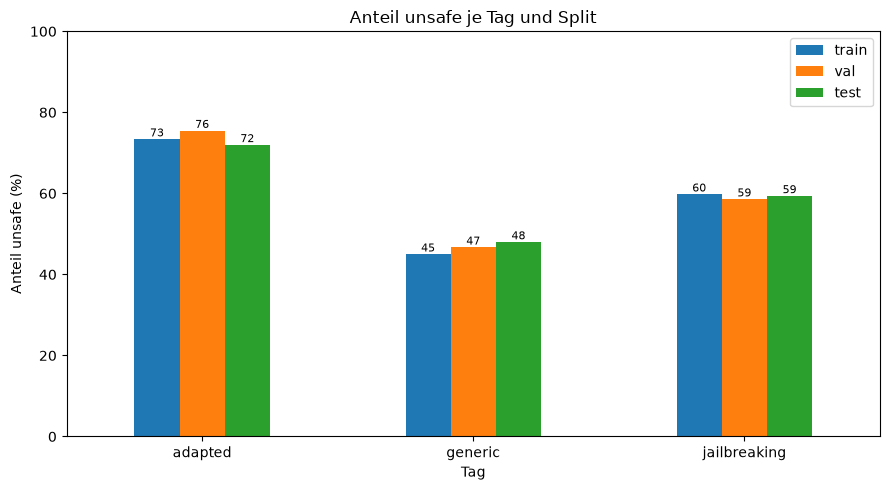

In [ ]:
ax = tag_tab.plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("Anteil unsafe (%)")
ax.set_xlabel("Tag")
ax.set_ylim(0, 100)
ax.set_title("Anteil unsafe je Tag und Split")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
plt.tight_layout()
plt.show()

## Schritt 10 (optional). Treemap
**Aufgabe:** Zeichne Familie und Kategorie als Treemap, am einfachsten mit `plotly.express.treemap(df, path=["familie", "kategorie"], values="n")`.

**Kontrolle:** Die Flächen entsprechen den Anteilen aus Schritt 5.

**Treemap:** Nennungen pro Familie und Kategorie im Train-Split als verschachtelte Kacheln: außen die Familie, innen die Kategorien. Die Fläche entspricht der Häufigkeit, angezeigt werden Name, Anzahl und Anteil am Gesamten.

In [ ]:
import plotly.express as px

tm = (train_long.dropna(subset=["familie"])
      .loc[lambda d: ~d["kategorie"].isin(nicht_in_grafiken)]   # Zusatzmarker nicht mitzählen
      .groupby(["familie", "kategorie"]).size()
      .reset_index(name="n"))

fig = px.treemap(tm, path=["familie", "kategorie"], values="n",
                 title="Train: Familien und Kategorien (ohne Needs Caution)")
fig.update_traces(textinfo="label+value+percent root")
fig.show()

## Notizen für die Arbeit
Halte hier Befunde fest, die du in den Text übernehmen willst, zum Beispiel
- Zeilen pro Split nach der Bereinigung
- Auffälligkeiten bei den Tags oder Kategorien
- Anteil der Finanz-Schlüsselwörter nach der Stichprobenprüfung
- Entscheidung zu Needs Caution